# Tasa de empleo

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "tasa-empleo"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Tasa de empleo"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la población de 15 a 64 años"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de la población de 15 a 64 años que tiene empleo.

**Cómo se lee.** Complementa la tasa de paro: no depende de cuántas personas buscan empleo, así que recoge también a quienes no trabajan ni lo buscan (estudiantes, personas que cuidan de otras, jubilados antes de los 65, desanimados). Un valor de 65 significa que de cada cien personas en edad de trabajar, sesenta y cinco tienen empleo.

**Limitaciones.**
- La tasa depende de la estructura de edades y de cuántos jóvenes estudian, además del mercado de trabajo.
- El objetivo de empleo de la Unión Europea para 2030 se mide de 20 a 64 años, no de 15 a 64.
- La serie de la OCDE de España empieza en 1999 y la tabla de Eurostat (`lfsi_emp_a`), en 2009.

## 2. Descarga

- **España, EE. UU., Canadá y OCDE:** OCDE, Encuestas de población activa (`OECD.SDD.TPS,DSD_LFS@DF_IALFS_EMP_WAP_Q`, versión 1.0): tasa de empleo (`EMP_WAP`), de 15 a 64 años (`Y15T64`), ambos sexos, sin desestacionalizar, frecuencia anual (`A`).
- **UE-27:** Eurostat `lfsi_emp_a`: ocupados (`EMP_LFS`) en % de la población (`PC_POP`), de 15 a 64 años, ambos sexos.
- **Solo para las notas:** Eurostat `lfsi_emp_a` para España (comparación con la OCDE) y la tasa de 20 a 64 años de España y la UE-27.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd

AREAS_OCDE = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde"}
DATAFLOW_EMP = "OECD.SDD.TPS,DSD_LFS@DF_IALFS_EMP_WAP_Q,1.0"
# Dimensiones: país . medida . unidad . transformación . ajuste . sexo . edad . actividad . frecuencia
CLAVE_EMP = "{AREA}.EMP_WAP.PT_WAP_SUB._Z.N._T.Y15T64._Z.A"
FILTROS_EU = {"indic_em": "EMP_LFS", "age": "Y15-64", "sex": "T", "unit": "PC_POP"}

oc, fuentes_oc = oecd.get(DATAFLOW_EMP, CLAVE_EMP, areas=AREAS_OCDE, desde=DESDE)
eu, fuentes_eu = eurostat.get("lfsi_emp_a", FILTROS_EU, geos={"EU27_2020": "ue27"}, desde=DESDE)
# Solo para las notas
eu_esp, _ = eurostat.get("lfsi_emp_a", FILTROS_EU, geos={"ES": "espana"}, desde=DESDE)
t2064, _ = eurostat.get("lfsi_emp_a", {**FILTROS_EU, "age": "Y20-64"}, geos={"ES": "espana", "EU27_2020": "ue27"}, desde=DESDE)
print(oc.groupby("serie")["periodo"].agg(["min", "max"]))
print(eu.groupby("serie")["periodo"].agg(["min", "max"]))

         min   max
serie             
canada  1976  2025
eeuu    1976  2024
espana  1999  2025
ocde    2007  2024
        min   max
serie            
ue27   2009  2025


## 3. Transformación

1. Las series se usan tal como las publican las fuentes: son tasas, sin transformar. La OCDE no publica la UE-27 en este dataflow y se usa Eurostat.
2. **Comparación de España** en la OCDE y en Eurostat, para las notas.
3. **Tasa de 20 a 64 años** (la del objetivo de la UE para 2030) del último año, para las notas.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


df = pd.concat([oc, eu], ignore_index=True)
fuentes = [*fuentes_oc, *fuentes_eu]
assert df["valor"].between(0, 100).all(), "porcentaje fuera de rango"

ULTIMO = int(t2064["periodo"].max())
NOTAS = [
    "España, EE. UU., Canadá y OCDE: OCDE, Encuestas de población activa (DSD_LFS@DF_IALFS_EMP_WAP_Q): ocupados de 15 a "
    "64 años en % de la población de esa edad, media anual. La serie de España de la OCDE empieza en "
    f"{int(serie(oc, 'espana').index.min())}.",
    "UE-27: Eurostat (lfsi_emp_a), de 15 a 64 años, ambos sexos, agregado de composición actual (EU27_2020).",
    f"El objetivo de empleo de la UE para 2030 se mide de 20 a 64 años: en {ULTIMO}, la tasa de ese tramo era del "
    f"{es(serie(t2064, 'espana')[ULTIMO])} % en España y del {es(serie(t2064, 'ue27')[ULTIMO])} % en la UE-27 "
    "(Eurostat, lfsi_emp_a).",
    nota_comparacion("Comparación de España en la OCDE y en Eurostat", serie(oc, "espana"), serie(eu_esp, "espana")),
    "Rupturas de serie de la EPA: renovación del cuestionario y de la metodología de la encuesta en 2005.",
]
for n in NOTAS:
    print("-", n)

- España, EE. UU., Canadá y OCDE: OCDE, Encuestas de población activa (DSD_LFS@DF_IALFS_EMP_WAP_Q): ocupados de 15 a 64 años en % de la población de esa edad, media anual. La serie de España de la OCDE empieza en 1999.
- UE-27: Eurostat (lfsi_emp_a), de 15 a 64 años, ambos sexos, agregado de composición actual (EU27_2020).
- El objetivo de empleo de la UE para 2030 se mide de 20 a 64 años: en 2025, la tasa de ese tramo era del 72,4 % en España y del 76,1 % en la UE-27 (Eurostat, lfsi_emp_a).
- Comparación de España en la OCDE y en Eurostat: en los 17 años comunes (2009-2025), la diferencia máxima es de 0,05 puntos, en 2010.
- Rupturas de serie de la EPA: renovación del cuestionario y de la metodología de la encuesta en 2005.


## 4. Visualización

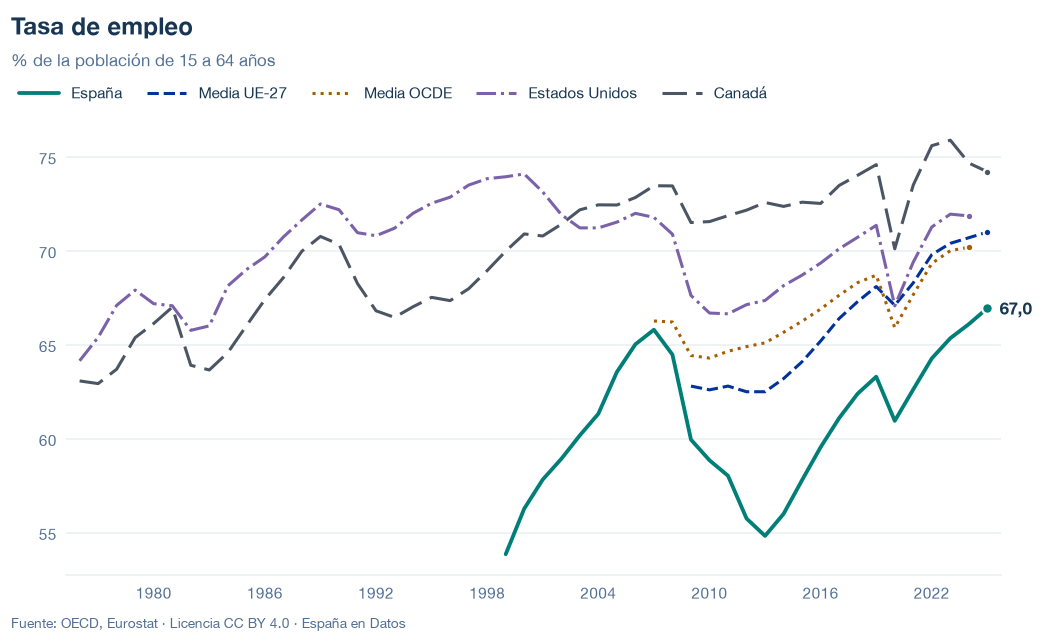

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/tasa-empleo.json y data/tasa-empleo.csv


## 6. Fuentes, notas y licencia

- OCDE, Encuestas de población activa: `OECD.SDD.TPS,DSD_LFS@DF_IALFS_EMP_WAP_Q,1.0` (`EMP_WAP`, `PT_WAP_SUB`, `N`, `_T`, `Y15T64`, `A`). El dataflow es infraanual pero publica también la frecuencia anual.
- Eurostat, `lfsi_emp_a` (`EMP_LFS`, `Y15-64`, `T`, `PC_POP`; `Y20-64` solo para las notas).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.